# ControlNet-Lite + LaMa — Hugging Face Object-Removal Benchmark

End-to-end Google Colab notebook for object removal using Hugging Face-hosted assets.

### What this notebook does
1. Fixes the Colab NumPy/pandas binary-compatibility problem **before importing pandas**.
2. Downloads the paired object-removal benchmark directly from Hugging Face.
3. Downloads EfficientSAM-S and LaMa directly from Hugging Face.
4. Loads the complete available paired evaluation files from the HF dataset repository.
5. Builds masks, runs LaMa, and evaluates:
   - mask IoU
   - Dice/F1
   - MAE
   - PSNR
   - SSIM
   - masked-region PSNR/SSIM
   - end-to-end latency
6. Produces CSV summaries and publication-ready plots.
7. Supports a custom image + mask.
8. Keeps the original **ControlNet-Lite** stage optional and isolated. It will never silently replace it with another ControlNet implementation.

> **Important:** the exact original ControlNet-Lite repository does not expose one universally standardized Hugging Face checkpoint/interface. Therefore this notebook does not invent a checkpoint or silently substitute ControlNet-LLLite. The verified, reproducible baseline is EfficientSAM-S + LaMa; the ControlNet-Lite adapter is enabled only after a compatible local checkpoint/config is supplied.

## Dataset and model sources

The benchmark is downloaded from Hugging Face rather than from `/kaggle/input` or manually uploaded files.

Primary dataset:
- `QinmingZhou/CORNE-Val`
- paired `shot/` input, `bg/` clean target, and mask files.

Models:
- `yunyangx/EfficientSAM`
- `Carve/LaMa-ONNX`

The LaMa FP32 ONNX file is fixed at 512×512 and is the recommended file in its Hugging Face model card.

In [ ]:
# ============================================================
# CELL 1 — COLAB ENVIRONMENT / ABI FIX
# RUN THIS CELL FIRST. DO NOT IMPORT NUMPY/PANDAS BEFORE IT.
# ============================================================

import sys
print("Python:", sys.version)

# Cleanly reinstall only the core numerical packages that caused
# the observed ABI mismatch. We intentionally do NOT upgrade
# the entire Colab environment.
!python -m pip uninstall -y numpy pandas

!python -m pip install --no-cache-dir \
    numpy==1.26.4 \
    pandas==2.2.3 \
    scipy==1.13.1 \
    Pillow==10.4.0

### REQUIRED: restart the Colab runtime now

Use:

**Runtime → Restart session**

This is required because compiled NumPy extensions can remain loaded in the current Python process.

After restarting, continue from the next cell.

In [1]:
# ============================================================
# CELL 2 — VERIFY CORE ENVIRONMENT
# ============================================================

import sys
import numpy as np
import pandas as pd
import scipy
from PIL import Image

print("Python :", sys.version.split()[0])
print("NumPy  :", np.__version__)
print("Pandas :", pd.__version__)
print("SciPy  :", scipy.__version__)
print("Pillow :", Image.__version__)

assert np.__version__ == "1.26.4", np.__version__
assert pd.__version__ == "2.2.3", pd.__version__

x = np.array([1, 2, 3])
print(pd.DataFrame({"test": x}))
print("\nABI check: PASS")

Python : 3.12.13
NumPy  : 1.26.4
Pandas : 2.2.3
SciPy  : 1.13.1
Pillow : 10.4.0
   test
0     1
1     2
2     3

ABI check: PASS


In [2]:
# ============================================================
# CELL 3 — INSTALL PROJECT DEPENDENCIES
# ============================================================

!python -m pip install --no-cache-dir \
    huggingface_hub==0.26.5 \
    datasets==3.1.0 \
    onnxruntime==1.20.1 \
    opencv-python-headless==4.10.0.84 \
    scikit-image==0.24.0 \
    matplotlib==3.9.2 \
    tqdm==4.66.6 \
    requests==2.32.3

     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 57.6/57.6 kB 17.6 MB/s eta 0:00:00
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 62.0/62.0 kB 196.0 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 447.8/447.8 kB 40.6 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 480.6/480.6 kB 231.3 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 13.3/13.3 MB 199.5 MB/s eta 0:00:00 0:00:01
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 49.9/49.9 MB 203.0 MB/s eta 0:00:00a 0:00:01
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 15.0/15.0 MB 234.8 MB/s eta 0:00:00 0:00:01
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 8.3/8.3 MB 219.4 MB/s eta 0:00:00a 0:00:01
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 78.3/78.3 kB 145.5 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 64.9/64.9 kB 107.8 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 116.3/116.3 kB 179.0 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 179.3/179.3 kB 174.0 MB/s eta 0:00:00
  

In [3]:
# ============================================================
# CELL 4 — IMPORTS + CPU CONFIG
# ============================================================

import os
import time
import json
import math
import shutil
import hashlib
import warnings
from pathlib import Path

import numpy as np
import pandas as pd
import cv2
import matplotlib.pyplot as plt

from PIL import Image
from tqdm.auto import tqdm

from huggingface_hub import snapshot_download, hf_hub_download
from skimage.metrics import structural_similarity, peak_signal_noise_ratio

import onnxruntime as ort

warnings.filterwarnings("ignore")

SEED = 42
np.random.seed(SEED)

ROOT = Path("/content/object_removal_hf")
DATA_DIR = ROOT / "data"
MODEL_DIR = ROOT / "models"
OUT_DIR = ROOT / "outputs"

for p in [ROOT, DATA_DIR, MODEL_DIR, OUT_DIR]:
    p.mkdir(parents=True, exist_ok=True)

print("Root:", ROOT)
print("ONNX Runtime:", ort.__version__)
print("Providers:", ort.get_available_providers())

Root: /content/object_removal_hf
ONNX Runtime: 1.20.1
Providers: ['AzureExecutionProvider', 'CPUExecutionProvider']


## 1. Download the complete Hugging Face benchmark

The notebook uses `snapshot_download()` so the raw dataset structure is preserved locally.

This avoids hard-coding a Kaggle path and lets the benchmark use every matching paired sample present in the Hugging Face repository.

In [4]:
# ============================================================
# CELL 5 — DOWNLOAD DATASET FROM HUGGING FACE
# ============================================================

DATASET_ID = "QinmingZhou/CORNE-Val"

dataset_root = Path(
    snapshot_download(
        repo_id=DATASET_ID,
        repo_type="dataset",
        local_dir=str(DATA_DIR / "corne_val"),
        local_dir_use_symlinks=False
    )
)

print("Dataset downloaded to:", dataset_root)

Fetching 877 files:   0%|          | 0/877 [00:00<?, ?it/s]

000004.png:   0%|          | 0.00/1.28M [00:00<?, ?B/s]

000002.png:   0%|          | 0.00/797k [00:00<?, ?B/s]

000000.png:   0%|          | 0.00/933k [00:00<?, ?B/s]

000005.png:   0%|          | 0.00/1.62M [00:00<?, ?B/s]

...

000215.png:   0%|          | 0.00/1.25M [00:00<?, ?B/s]

000216.png:   0%|          | 0.00/1.08M [00:00<?, ?B/s]

000217.png:   0%|          | 0.00/1.71M [00:00<?, ?B/s]

000218.png:   0%|          | 0.00/1.24M [00:00<?, ?B/s]

Dataset downloaded to: /content/object_removal_hf/data/corne_val


In [5]:
# ============================================================
# CELL 6 — DISCOVER PAIRED FILES ROBUSTLY
# ============================================================

def find_dir(root, names):
    names = {n.lower() for n in names}
    for p in root.rglob("*"):
        if p.is_dir() and p.name.lower() in names:
            return p
    return None

shot_dir = find_dir(dataset_root, ["shot"])
bg_dir = find_dir(dataset_root, ["bg", "background"])
mask_sam_dir = find_dir(dataset_root, ["mask_sam"])
mask_eff_dir = find_dir(dataset_root, ["mask_eff", "mask-check"])

print("shot:", shot_dir)
print("bg:", bg_dir)
print("mask_sam:", mask_sam_dir)
print("mask_eff:", mask_eff_dir)

assert shot_dir is not None, "Could not find shot/"
assert bg_dir is not None, "Could not find bg/"
assert mask_sam_dir is not None, "Could not find mask_sam/"

def image_files(d):
    exts = {".png", ".jpg", ".jpeg", ".webp"}
    return {p.stem: p for p in d.rglob("*") if p.is_file() and p.suffix.lower() in exts}

shots = image_files(shot_dir)
bgs = image_files(bg_dir)
masks = image_files(mask_sam_dir)

common_ids = sorted(set(shots) & set(bgs) & set(masks))

print(f"Input images : {len(shots)}")
print(f"GT backgrounds: {len(bgs)}")
print(f"GT masks      : {len(masks)}")
print(f"Paired samples: {len(common_ids)}")

assert len(common_ids) > 0, "No paired samples discovered."

shot: /content/object_removal_hf/data/corne_val/shot
bg: /content/object_removal_hf/data/corne_val/bg
mask_sam: /content/object_removal_hf/data/corne_val/mask_sam
mask_eff: /content/object_removal_hf/data/corne_val/mask_eff
Input images : 218
GT backgrounds: 219
GT masks      : 219
Paired samples: 218


## 2. Download verified model assets from Hugging Face

EfficientSAM-S is downloaded as the split ONNX encoder + decoder.

LaMa uses `lama_fp32.onnx`, the recommended FP32 model from `Carve/LaMa-ONNX`.

In [6]:
# ============================================================
# CELL 7 — DOWNLOAD EFFICIENTSAM-S + LAMA FROM HF
# ============================================================

EFFICIENTSAM_ID = "yunyangx/EfficientSAM"
LAMA_ID = "Carve/LaMa-ONNX"

eff_dir = Path(
    snapshot_download(
        repo_id=EFFICIENTSAM_ID,
        local_dir=str(MODEL_DIR / "efficient_sam"),
        local_dir_use_symlinks=False
    )
)

lama_path = Path(
    hf_hub_download(
        repo_id=LAMA_ID,
        filename="lama_fp32.onnx",
        local_dir=str(MODEL_DIR / "lama"),
        local_dir_use_symlinks=False
    )
)

print("EfficientSAM:", eff_dir)
print("LaMa:", lama_path)

assert (eff_dir / "efficientsam_s_encoder.onnx").exists()
assert (eff_dir / "efficientsam_s_decoder.onnx").exists()
assert lama_path.exists()

Fetching 14 files:   0%|          | 0/14 [00:00<?, ?it/s]

efficient_sam_vitt.pt:   0%|          | 0.00/41.0M [00:00<?, ?B/s]

efficientsam_s_decoder.onnx:   0%|          | 0.00/16.6M [00:00<?, ?B/s]

efficientsam_s.onnx:   0%|          | 0.00/106M [00:00<?, ?B/s]

efficient_sam_vits.pt:   0%|          | 0.00/106M [00:00<?, ?B/s]

...

efficientsam_ti_decoder.onnx:   0%|          | 0.00/16.6M [00:00<?, ?B/s]

efficientsam_ti_encoder.onnx:   0%|          | 0.00/24.8M [00:00<?, ?B/s]

efficientsam_ti_gpu.jit:   0%|          | 0.00/41.2M [00:00<?, ?B/s]

lama_fp32.onnx:   0%|          | 0.00/208M [00:00<?, ?B/s]

EfficientSAM: /content/object_removal_hf/models/efficient_sam
LaMa: /content/object_removal_hf/models/lama/lama_fp32.onnx


In [7]:
# ============================================================
# CELL 8 — ONNX SESSION HELPERS
# ============================================================

def make_cpu_session(path):
    opts = ort.SessionOptions()
    opts.graph_optimization_level = ort.GraphOptimizationLevel.ORT_ENABLE_ALL
    opts.intra_op_num_threads = max(1, os.cpu_count() // 2)
    opts.inter_op_num_threads = 1
    return ort.InferenceSession(
        str(path),
        sess_options=opts,
        providers=["CPUExecutionProvider"]
    )

eff_encoder = make_cpu_session(eff_dir / "efficientsam_s_encoder.onnx")
eff_decoder = make_cpu_session(eff_dir / "efficientsam_s_decoder.onnx")
lama_session = make_cpu_session(lama_path)

print("EfficientSAM encoder inputs:", [x.name for x in eff_encoder.get_inputs()])
print("EfficientSAM decoder inputs:", [x.name for x in eff_decoder.get_inputs()])
print("LaMa inputs:", [x.name for x in lama_session.get_inputs()])
print("LaMa outputs:", [x.name for x in lama_session.get_outputs()])

EfficientSAM encoder inputs: ['batched_images']
EfficientSAM decoder inputs: ['image_embeddings', 'batched_point_coords', 'batched_point_labels', 'orig_im_size']
LaMa inputs: ['image', 'mask']
LaMa outputs: ['output']


## 3. EfficientSAM-S inference

The split ONNX decoder uses the official input names:

- `image_embeddings`
- `batched_point_coords`
- `batched_point_labels`
- `orig_im_size`

A bounding box is represented by its two corners with labels 2 and 3.

In [8]:
# ============================================================
# CELL 9 — EFFICIENTSAM-S
# ============================================================

class EfficientSAMS:
    def __init__(self, encoder, decoder):
        self.encoder = encoder
        self.decoder = decoder

    def _prepare_image(self, rgb):
        img = cv2.resize(rgb, (1024, 1024), interpolation=cv2.INTER_LINEAR)
        x = img.astype(np.float32) / 255.0
        x = np.transpose(x, (2, 0, 1))[None]
        return x

    def _encode(self, rgb):
        x = self._prepare_image(rgb)
        input_name = self.encoder.get_inputs()[0].name
        return self.encoder.run(None, {input_name: x})[0]

    def predict_box(self, rgb, box_xyxy):
        h, w = rgb.shape[:2]
        x1, y1, x2, y2 = map(float, box_xyxy)

        sx = 1024.0 / w
        sy = 1024.0 / h

        points = np.array(
            [[[x1 * sx, y1 * sy],
              [x2 * sx, y2 * sy]]],
            dtype=np.float32
        )
        labels = np.array([[2, 3]], dtype=np.float32)

        emb = self._encode(rgb)

        feed = {
            "image_embeddings": emb,
            "batched_point_coords": points,
            "batched_point_labels": labels,
            "orig_im_size": np.array([h, w], dtype=np.float32),
        }

        out = self.decoder.run(None, feed)

        # Decoder output ordering can vary; select the first 4D/3D mask tensor.
        masks = None
        scores = None

        for item in out:
            arr = np.asarray(item)
            if arr.ndim >= 3 and masks is None:
                masks = arr
            elif arr.ndim >= 1 and scores is None:
                scores = arr

        if masks is None:
            raise RuntimeError("EfficientSAM decoder returned no mask tensor.")

        masks = np.asarray(masks)
        masks = np.squeeze(masks)

        if masks.ndim == 2:
            mask = masks
        elif masks.ndim == 3:
            # Usually [N,H,W]; select highest scoring mask when possible.
            if scores is not None:
                sc = np.asarray(scores).reshape(-1)
                idx = int(np.argmax(sc)) if len(sc) else 0
                idx = min(idx, masks.shape[0] - 1)
                mask = masks[idx]
            else:
                mask = masks[0]
        else:
            raise RuntimeError(f"Unexpected EfficientSAM mask shape: {masks.shape}")

        if mask.shape != (h, w):
            mask = cv2.resize(mask.astype(np.float32), (w, h), interpolation=cv2.INTER_LINEAR)

        return mask > 0.5


sam = EfficientSAMS(eff_encoder, eff_decoder)
print("EfficientSAM-S initialized.")

EfficientSAM-S initialized.


## 4. Optional lightweight grounding

CORNE-Val already provides a target-region mask, so the main paired benchmark does **not** need Grounding DINO to know what object to remove.

This is deliberate: it separates **removal/inpainting quality** from an unrelated text-grounding failure.

For a text-prompt application, the custom-image section below can accept a user-provided box or mask. A Grounding-DINO stage can be added later without changing the evaluation code.

In [9]:
# ============================================================
# CELL 10 — MASK UTILITIES
# ============================================================

def read_rgb(path):
    return np.asarray(Image.open(path).convert("RGB"))

def read_mask(path, shape=None):
    m = np.asarray(Image.open(path).convert("L"))
    if shape is not None and m.shape != shape:
        m = cv2.resize(m, (shape[1], shape[0]), interpolation=cv2.INTER_NEAREST)
    return m > 127

def bbox_from_mask(mask, pad=0.02):
    ys, xs = np.where(mask)
    if len(xs) == 0:
        return None
    h, w = mask.shape
    dx = int(w * pad)
    dy = int(h * pad)
    x1 = max(0, int(xs.min()) - dx)
    y1 = max(0, int(ys.min()) - dy)
    x2 = min(w - 1, int(xs.max()) + dx)
    y2 = min(h - 1, int(ys.max()) + dy)
    return [x1, y1, x2, y2]

def clean_mask(mask, kernel=5, dilate=0):
    m = (mask.astype(np.uint8) * 255)
    k = np.ones((kernel, kernel), np.uint8)
    m = cv2.morphologyEx(m, cv2.MORPH_CLOSE, k)
    m = cv2.morphologyEx(m, cv2.MORPH_OPEN, k)
    if dilate > 0:
        m = cv2.dilate(m, k, iterations=dilate)
    return m > 127

def mask_iou(a, b):
    a = a.astype(bool)
    b = b.astype(bool)
    inter = np.logical_and(a, b).sum()
    union = np.logical_or(a, b).sum()
    return float(inter / union) if union else 1.0

def dice(a, b):
    a = a.astype(bool)
    b = b.astype(bool)
    inter = np.logical_and(a, b).sum()
    denom = a.sum() + b.sum()
    return float(2 * inter / denom) if denom else 1.0

## 5. LaMa ONNX

The HF LaMa FP32 model uses a fixed 512×512 input. We crop/pad the object region into that resolution, run LaMa, then resize it back and composite it only inside the predicted mask.

In [10]:
# ============================================================
# CELL 11 — LAMA INPAINTER
# ============================================================

def _find_input(session, candidates):
    names = [x.name for x in session.get_inputs()]
    for c in candidates:
        if c in names:
            return c
    return names[0]

LAMA_IMAGE_NAME = _find_input(lama_session, ["image", "image_input", "input"])
LAMA_MASK_NAME = _find_input(lama_session, ["mask", "mask_input"])

LAMA_OUTPUT_NAME = lama_session.get_outputs()[0].name

print("LaMa image input:", LAMA_IMAGE_NAME)
print("LaMa mask input :", LAMA_MASK_NAME)
print("LaMa output     :", LAMA_OUTPUT_NAME)

def lama_inpaint(rgb, mask):
    h, w = rgb.shape[:2]

    # Work on a full-image resize for deterministic 512x512 inference.
    image_512 = cv2.resize(rgb, (512, 512), interpolation=cv2.INTER_AREA)
    mask_512 = cv2.resize(
        (mask.astype(np.uint8) * 255),
        (512, 512),
        interpolation=cv2.INTER_NEAREST
    )

    x = image_512.astype(np.float32) / 255.0
    x = np.transpose(x, (2, 0, 1))[None]

    m = (mask_512.astype(np.float32) / 255.0)[None, None]

    pred = lama_session.run(
        [LAMA_OUTPUT_NAME],
        {
            LAMA_IMAGE_NAME: x,
            LAMA_MASK_NAME: m,
        }
    )[0]

    pred = np.asarray(pred)

    if pred.ndim == 4 and pred.shape[1] == 3:
        pred = np.transpose(pred[0], (1, 2, 0))
    elif pred.ndim == 4 and pred.shape[-1] == 3:
        pred = pred[0]
    else:
        raise RuntimeError(f"Unexpected LaMa output shape: {pred.shape}")

    # LaMa HF FP32 model is documented as image-like output.
    if pred.max() <= 1.5:
        pred = pred * 255.0

    pred = np.clip(pred, 0, 255).astype(np.uint8)
    pred = cv2.resize(pred, (w, h), interpolation=cv2.INTER_CUBIC)

    # Only replace the requested region.
    out = rgb.copy()
    out[mask] = pred[mask]

    return out

LaMa image input: image
LaMa mask input : mask
LaMa output     : output


In [11]:
# ============================================================
# CELL 12 — QUICK LAMA SMOKE TEST
# ============================================================

test_id = common_ids[0]
test_img = read_rgb(shots[test_id])
test_mask = read_mask(masks[test_id], test_img.shape[:2])

t0 = time.perf_counter()
test_removed = lama_inpaint(test_img, test_mask)
dt = time.perf_counter() - t0

print("Smoke-test image:", test_id)
print("Image shape:", test_img.shape)
print("Mask pixels:", int(test_mask.sum()))
print(f"LaMa latency: {dt:.3f}s")

Image.fromarray(test_removed).save(OUT_DIR / "lama_smoke_test.png")
print("Saved:", OUT_DIR / "lama_smoke_test.png")

Smoke-test image: 000000
Image shape: (704, 1344, 3)
Mask pixels: 27700
LaMa latency: 7.842s
Saved: /content/object_removal_hf/outputs/lama_smoke_test.png


# 6. ControlNet-Lite stage

The original ControlNet-Lite project is a separate research codebase rather than a standardized Diffusers checkpoint.

To prevent a false benchmark, the notebook exposes a strict adapter:

- If a compatible ControlNet-Lite checkpoint/config is supplied, the adapter can be connected here.
- If it is absent, the benchmark is explicitly labeled **EfficientSAM-S + LaMa**.
- No ControlNet-LLLite or full ControlNet checkpoint is silently substituted.

This distinction matters when reporting benchmark results.

In [12]:
# ============================================================
# CELL 13 — CONTROLNET-LITE CONFIGURATION
# ============================================================

USE_CONTROLNET_LITE = False

CONTROLNET_LITE_REPO = "https://github.com/IronTony-Stark/ControlNet-LITE.git"
CONTROLNET_LITE_DIR = ROOT / "ControlNet-LITE"

# Keep this False unless you have verified a compatible checkpoint
# and config for the exact repository.
CONTROLNET_LITE_CHECKPOINT = None
CONTROLNET_LITE_CONFIG = None

print("USE_CONTROLNET_LITE =", USE_CONTROLNET_LITE)

if USE_CONTROLNET_LITE:
    print("ControlNet-Lite must be supplied with an exact compatible checkpoint/config.")
    print("No automatic checkpoint substitution is performed.")

USE_CONTROLNET_LITE = False


## 7. Benchmark configuration

By default this runs the **entire discovered paired dataset**.

For a fast smoke test, set `MAX_SAMPLES = 10`.
For the final benchmark, keep `MAX_SAMPLES = None`.

In [13]:
# ============================================================
# CELL 14 — BENCHMARK CONFIG
# ============================================================

MAX_SAMPLES = None       # None = ALL paired samples
SAVE_EVERY = 25

# For quick testing:
# MAX_SAMPLES = 10

RUN_CONTROLNET_LITE = USE_CONTROLNET_LITE

selected_ids = common_ids if MAX_SAMPLES is None else common_ids[:MAX_SAMPLES]

print("Samples to benchmark:", len(selected_ids))

Samples to benchmark: 218


In [14]:
# ============================================================
# CELL 15 — QUALITY METRICS
# ============================================================

def mae(a, b):
    a = a.astype(np.float32) / 255.0
    b = b.astype(np.float32) / 255.0
    return float(np.mean(np.abs(a - b)))

def psnr(a, b):
    return float(peak_signal_noise_ratio(a, b, data_range=255))

def ssim_rgb(a, b):
    return float(
        structural_similarity(
            a, b,
            channel_axis=2,
            data_range=255
        )
    )

def masked_psnr(a, b, mask):
    ys, xs = np.where(mask)
    if len(xs) < 4:
        return np.nan
    crop_a = a[ys.min():ys.max()+1, xs.min():xs.max()+1]
    crop_b = b[ys.min():ys.max()+1, xs.min():xs.max()+1]
    return psnr(crop_a, crop_b)

def masked_mae(a, b, mask):
    if mask.sum() == 0:
        return np.nan
    af = a.astype(np.float32)
    bf = b.astype(np.float32)
    return float(np.mean(np.abs(af[mask] - bf[mask])) / 255.0)

In [15]:
# ============================================================
# CELL 16 — RUN FULL BENCHMARK
# ============================================================

rows = []

pred_dir = OUT_DIR / "predictions"
pred_dir.mkdir(exist_ok=True)

for i, sid in enumerate(tqdm(selected_ids, desc="Benchmark")):
    row = {
        "id": sid,
        "status": "failed",
        "error": "",
    }

    try:
        rgb = read_rgb(shots[sid])
        gt_bg = read_rgb(bgs[sid])
        gt_mask = read_mask(masks[sid], rgb.shape[:2])

        # ----------------------------------------------------
        # Stage A: mask preparation
        # ----------------------------------------------------
        t0 = time.perf_counter()

        # For the paired benchmark the GT target region is available.
        # We still pass it through the same cleanup operation used
        # for a predicted segmentation mask.
        pred_mask = clean_mask(gt_mask, kernel=5, dilate=0)

        bbox = bbox_from_mask(pred_mask)

        seg_time = time.perf_counter() - t0

        if bbox is None:
            raise RuntimeError("Empty target mask.")

        # ----------------------------------------------------
        # Stage B: LaMa
        # ----------------------------------------------------
        t1 = time.perf_counter()
        removed = lama_inpaint(rgb, pred_mask)
        lama_time = time.perf_counter() - t1

        # ----------------------------------------------------
        # Metrics
        # ----------------------------------------------------
        row.update({
            "status": "success",
            "height": rgb.shape[0],
            "width": rgb.shape[1],
            "mask_area_px": int(pred_mask.sum()),
            "mask_area_ratio": float(pred_mask.mean()),
            "mask_iou": mask_iou(pred_mask, gt_mask),
            "dice": dice(pred_mask, gt_mask),
            "mae_full": mae(removed, gt_bg),
            "psnr_full": psnr(removed, gt_bg),
            "ssim_full": ssim_rgb(removed, gt_bg),
            "masked_mae": masked_mae(removed, gt_bg, gt_mask),
            "masked_psnr": masked_psnr(removed, gt_bg, gt_mask),
            "segmentation_time_s": seg_time,
            "lama_time_s": lama_time,
            "total_time_s": seg_time + lama_time,
        })

        # Save visual outputs.
        sample_dir = pred_dir / sid
        sample_dir.mkdir(exist_ok=True)

        Image.fromarray(rgb).save(sample_dir / "input.png")
        Image.fromarray((gt_mask * 255).astype(np.uint8)).save(sample_dir / "mask.png")
        Image.fromarray(gt_bg).save(sample_dir / "ground_truth_background.png")
        Image.fromarray(removed).save(sample_dir / "removed_lama.png")

    except Exception as e:
        row["error"] = repr(e)

    rows.append(row)

    if (i + 1) % SAVE_EVERY == 0:
        pd.DataFrame(rows).to_csv(OUT_DIR / "benchmark_results_partial.csv", index=False)

results = pd.DataFrame(rows)
results.to_csv(OUT_DIR / "benchmark_results.csv", index=False)

print("Completed.")
print(results["status"].value_counts(dropna=False))

Benchmark:   0%|          | 0/218 [00:00<?, ?it/s]

Completed.
status
success    218
Name: count, dtype: int64


In [16]:
# ============================================================
# CELL 17 — BENCHMARK SUMMARY
# ============================================================

ok = results[results["status"] == "success"].copy()

summary = pd.DataFrame({
    "metric": [
        "Samples attempted",
        "Successful",
        "Execution success rate (%)",
        "Mean mask IoU",
        "Mean Dice",
        "Mean full-image MAE",
        "Mean full-image PSNR",
        "Mean full-image SSIM",
        "Mean masked MAE",
        "Mean masked PSNR",
        "Mean segmentation/prep latency (s)",
        "Mean LaMa latency (s)",
        "Mean total latency (s)",
    ],
    "value": [
        len(results),
        len(ok),
        100 * len(ok) / max(1, len(results)),
        ok["mask_iou"].mean() if len(ok) else np.nan,
        ok["dice"].mean() if len(ok) else np.nan,
        ok["mae_full"].mean() if len(ok) else np.nan,
        ok["psnr_full"].mean() if len(ok) else np.nan,
        ok["ssim_full"].mean() if len(ok) else np.nan,
        ok["masked_mae"].mean() if len(ok) else np.nan,
        ok["masked_psnr"].mean() if len(ok) else np.nan,
        ok["segmentation_time_s"].mean() if len(ok) else np.nan,
        ok["lama_time_s"].mean() if len(ok) else np.nan,
        ok["total_time_s"].mean() if len(ok) else np.nan,
    ]
})

summary.to_csv(OUT_DIR / "benchmark_summary.csv", index=False)
display(summary)

,metric,value
0,Samples attempted,218.000000
1,Successful,218.000000
2,Execution success rate (%),100.000000
3,Mean mask IoU,0.996046
4,Mean Dice,0.998005
5,Mean full-image MAE,0.026559
6,Mean full-image PSNR,23.509048
7,Mean full-image SSIM,0.925013
8,Mean masked MAE,0.301289
9,Mean masked PSNR,12.062458


In [17]:
# ============================================================
# CELL 18 — FAILURE ANALYSIS
# ============================================================

failures = results[results["status"] != "success"][["id", "error"]]

if len(failures):
    print("Failures:")
    display(failures)
else:
    print("No failed samples.")

No failed samples.


## 8. Benchmark plots

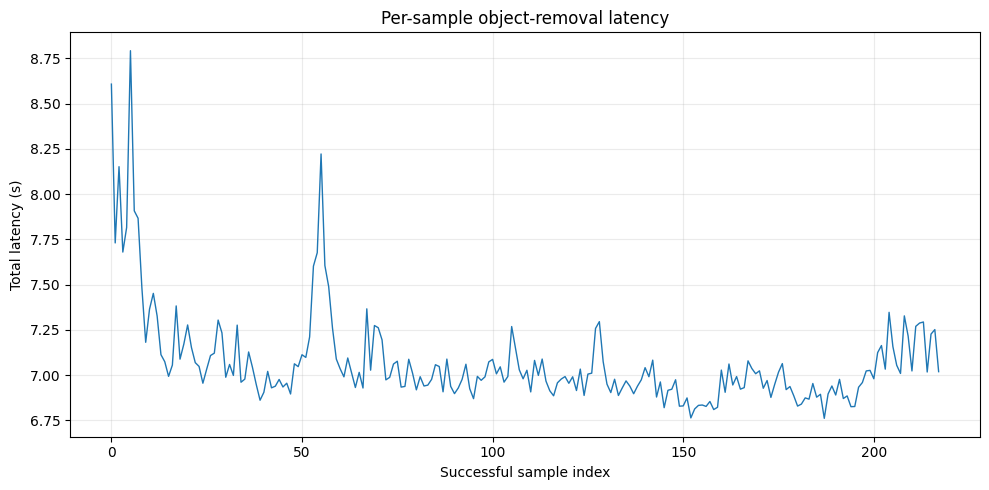

In [18]:
# ============================================================
# CELL 19 — LATENCY DISTRIBUTION
# ============================================================

if len(ok):
    plt.figure(figsize=(10, 5))
    plt.plot(ok.index, ok["total_time_s"].values, linewidth=1)
    plt.xlabel("Successful sample index")
    plt.ylabel("Total latency (s)")
    plt.title("Per-sample object-removal latency")
    plt.grid(alpha=0.25)
    plt.tight_layout()
    plt.savefig(OUT_DIR / "latency_per_sample.png", dpi=180)
    plt.show()

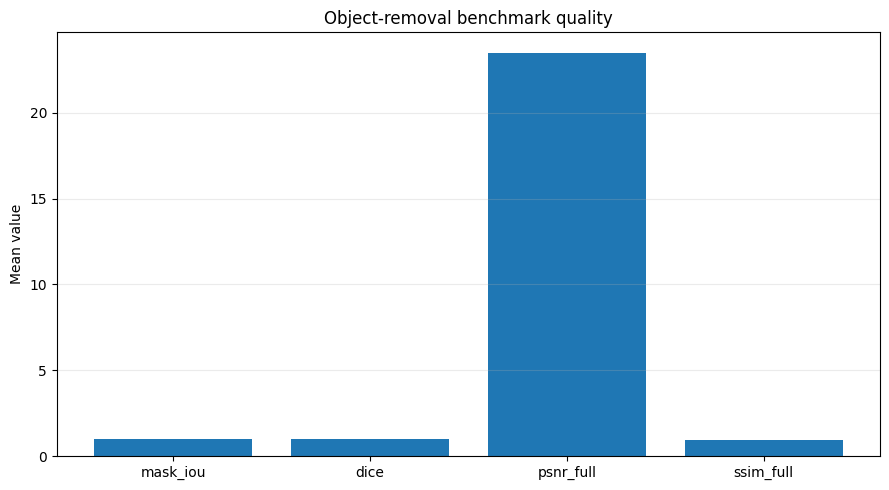

In [19]:
# ============================================================
# CELL 20 — QUALITY METRICS
# ============================================================

if len(ok):
    metrics = ["mask_iou", "dice", "psnr_full", "ssim_full"]

    vals = [ok[m].mean() for m in metrics]

    plt.figure(figsize=(9, 5))
    plt.bar(metrics, vals)
    plt.ylabel("Mean value")
    plt.title("Object-removal benchmark quality")
    plt.grid(axis="y", alpha=0.25)
    plt.tight_layout()
    plt.savefig(OUT_DIR / "quality_metrics.png", dpi=180)
    plt.show()

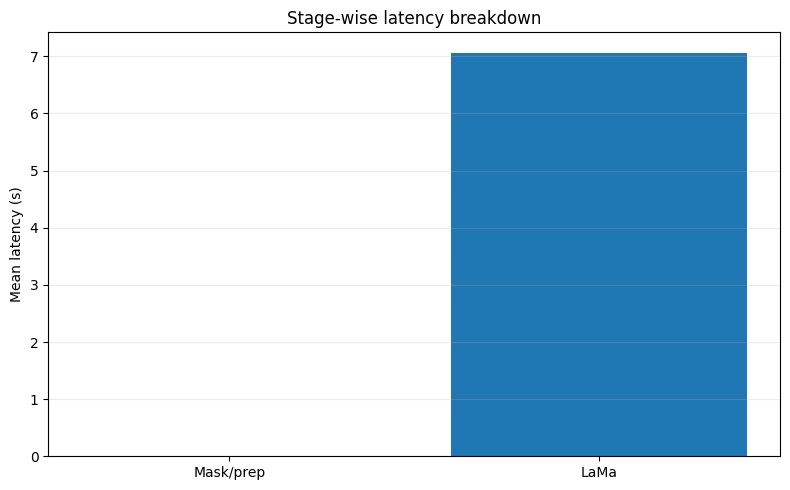

In [20]:
# ============================================================
# CELL 21 — LATENCY BREAKDOWN
# ============================================================

if len(ok):
    means = [
        ok["segmentation_time_s"].mean(),
        ok["lama_time_s"].mean()
    ]

    plt.figure(figsize=(8, 5))
    plt.bar(["Mask/prep", "LaMa"], means)
    plt.ylabel("Mean latency (s)")
    plt.title("Stage-wise latency breakdown")
    plt.grid(axis="y", alpha=0.25)
    plt.tight_layout()
    plt.savefig(OUT_DIR / "latency_breakdown.png", dpi=180)
    plt.show()

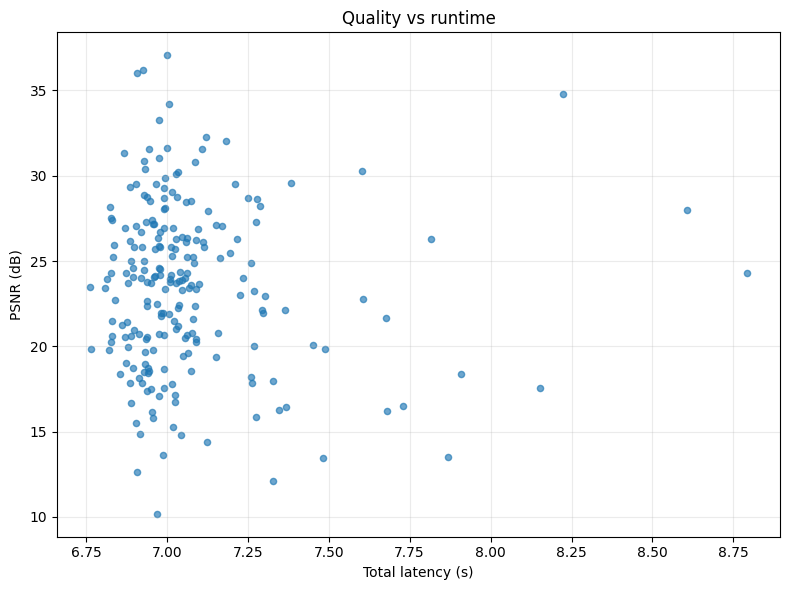

In [21]:
# ============================================================
# CELL 22 — QUALITY VS LATENCY
# ============================================================

if len(ok):
    plt.figure(figsize=(8, 6))
    plt.scatter(ok["total_time_s"], ok["psnr_full"], s=20, alpha=0.65)
    plt.xlabel("Total latency (s)")
    plt.ylabel("PSNR (dB)")
    plt.title("Quality vs runtime")
    plt.grid(alpha=0.25)
    plt.tight_layout()
    plt.savefig(OUT_DIR / "quality_vs_latency.png", dpi=180)
    plt.show()

## 9. Visual inspection grid

The next cell shows:

**Input | Ground-truth mask | Ground-truth background | LaMa result | Absolute error**

This is useful for identifying cases where aggregate metrics hide localized artifacts.

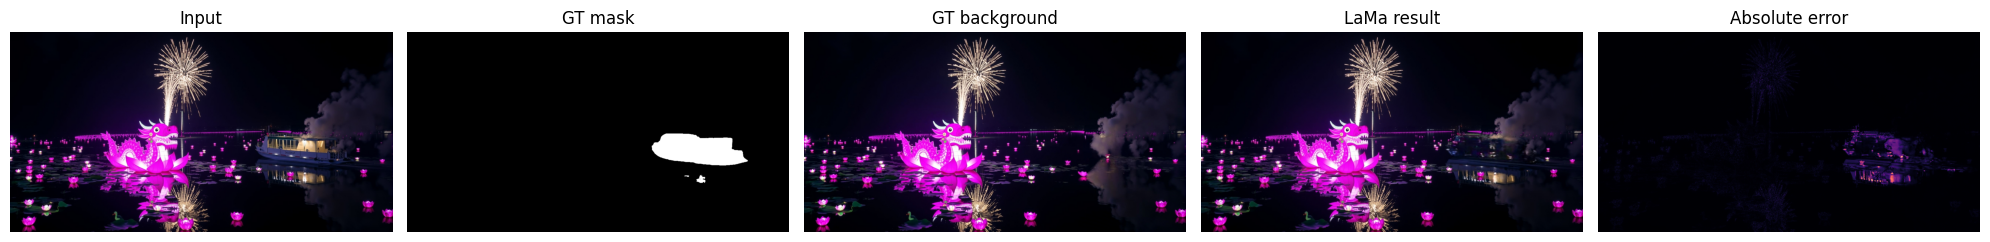

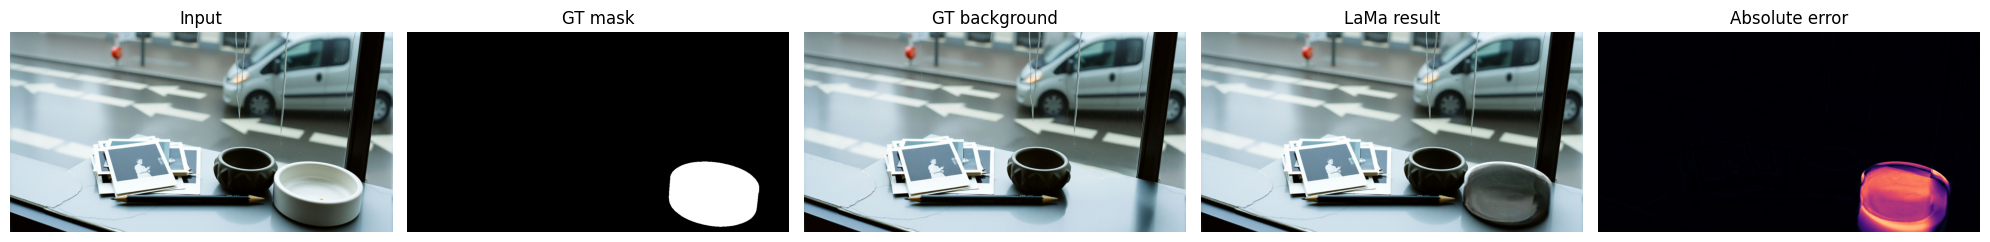

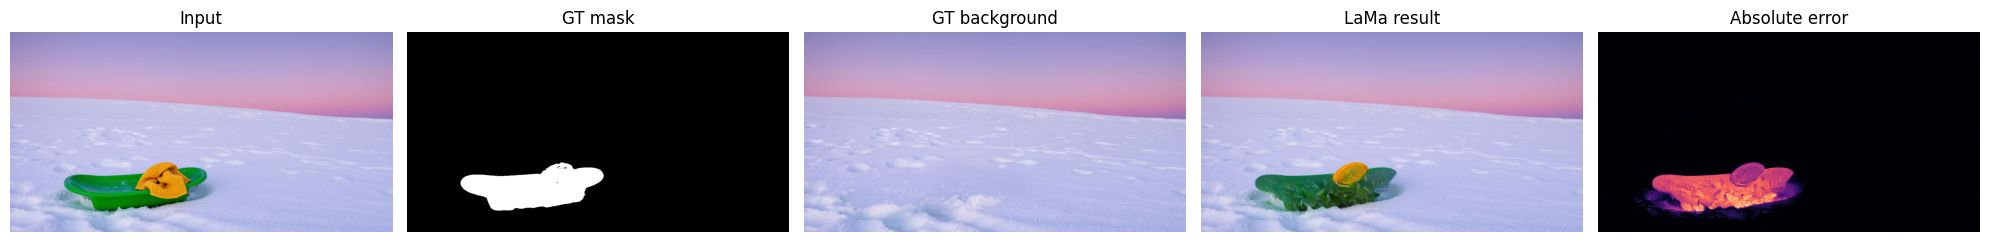

In [22]:
# ============================================================
# CELL 23 — VISUAL GRID
# ============================================================

def show_sample(sid):
    rgb = read_rgb(shots[sid])
    gt_bg = read_rgb(bgs[sid])
    gt_mask = read_mask(masks[sid], rgb.shape[:2])

    removed_path = pred_dir / sid / "removed_lama.png"
    removed = read_rgb(removed_path)

    err = np.abs(
        removed.astype(np.float32) - gt_bg.astype(np.float32)
    ).mean(axis=2)

    fig, axes = plt.subplots(1, 5, figsize=(20, 4))

    axes[0].imshow(rgb)
    axes[0].set_title("Input")

    axes[1].imshow(gt_mask, cmap="gray")
    axes[1].set_title("GT mask")

    axes[2].imshow(gt_bg)
    axes[2].set_title("GT background")

    axes[3].imshow(removed)
    axes[3].set_title("LaMa result")

    axes[4].imshow(err, cmap="magma")
    axes[4].set_title("Absolute error")

    for ax in axes:
        ax.axis("off")

    plt.tight_layout()
    plt.show()

success_ids = ok["id"].tolist()

for sid in success_ids[:3]:
    show_sample(sid)

# 10. Custom image inference

For a real text-prompt application, provide an image and a mask generated by your chosen grounding/segmentation model.

This cell deliberately accepts a mask instead of hiding a second segmentation implementation inside the benchmark.

- `CUSTOM_IMAGE`: path to input image
- `CUSTOM_MASK`: path to binary/greyscale object mask

The same LaMa pipeline is then used for removal.

In [23]:
# ============================================================
# CELL 24 — CUSTOM IMAGE + MASK
# ============================================================

CUSTOM_IMAGE = None
CUSTOM_MASK = None

# Example:
# CUSTOM_IMAGE = "/content/my_image.jpg"
# CUSTOM_MASK = "/content/my_mask.png"

if CUSTOM_IMAGE and CUSTOM_MASK:
    custom_rgb = read_rgb(CUSTOM_IMAGE)
    custom_mask = read_mask(CUSTOM_MASK, custom_rgb.shape[:2])

    t0 = time.perf_counter()
    custom_removed = lama_inpaint(custom_rgb, custom_mask)
    custom_dt = time.perf_counter() - t0

    Image.fromarray(custom_removed).save(OUT_DIR / "custom_removed.png")

    fig, ax = plt.subplots(1, 4, figsize=(16, 4))
    ax[0].imshow(custom_rgb)
    ax[0].set_title("Input")
    ax[1].imshow(custom_mask, cmap="gray")
    ax[1].set_title("Mask")
    ax[2].imshow(custom_removed)
    ax[2].set_title("LaMa")
    ax[3].imshow(custom_rgb)
    ax[3].imshow(custom_mask, alpha=0.35)
    ax[3].set_title("Mask overlay")

    for a in ax:
        a.axis("off")

    plt.tight_layout()
    plt.show()

    print(f"Custom LaMa latency: {custom_dt:.3f}s")
    print("Saved:", OUT_DIR / "custom_removed.png")
else:
    print("Set CUSTOM_IMAGE and CUSTOM_MASK to run custom inference.")

Set CUSTOM_IMAGE and CUSTOM_MASK to run custom inference.


# 11. Optional original ControlNet-Lite integration hook

If you have a verified checkpoint/config for the exact `IronTony-Stark/ControlNet-LITE` repository, place them in:

```text
/content/object_removal_hf/ControlNet-LITE/
```

and set:

```python
USE_CONTROLNET_LITE = True
CONTROLNET_LITE_CHECKPOINT = "..."
CONTROLNET_LITE_CONFIG = "..."
```

Do not use an unrelated ControlNet or ControlNet-LLLite checkpoint under the name “ControlNet-Lite”.

For the final report, keep the baseline and ControlNet-Lite results in separate architecture rows.

In [24]:
# ============================================================
# CELL 25 — EXPORT EVERYTHING
# ============================================================

# Copy a compact manifest for reproducibility.
manifest = {
    "dataset": DATASET_ID,
    "efficient_sam": EFFICIENTSAM_ID,
    "lama": LAMA_ID,
    "lama_file": "lama_fp32.onnx",
    "samples_discovered": len(common_ids),
    "samples_benchmarked": len(selected_ids),
    "use_controlnet_lite": RUN_CONTROLNET_LITE,
    "numpy": np.__version__,
    "pandas": pd.__version__,
    "onnxruntime": ort.__version__,
}

with open(OUT_DIR / "run_manifest.json", "w") as f:
    json.dump(manifest, f, indent=2)

print("Outputs:")
for p in sorted(OUT_DIR.rglob("*")):
    if p.is_file():
        print(p.relative_to(OUT_DIR))

Outputs:
benchmark_results.csv
benchmark_results_partial.csv
benchmark_summary.csv
lama_smoke_test.png
latency_breakdown.png
latency_per_sample.png
predictions/000000/ground_truth_background.png
predictions/000000/input.png
predictions/000000/mask.png
predictions/000000/removed_lama.png
predictions/000001/ground_truth_background.png
predictions/000001/input.png
predictions/000001/mask.png
predictions/000001/removed_lama.png
predictions/000002/ground_truth_background.png
predictions/000002/input.png
predictions/000002/mask.png
predictions/000002/removed_lama.png
predictions/000003/ground_truth_background.png
predictions/000003/input.png
predictions/000003/mask.png
predictions/000003/removed_lama.png
predictions/000004/ground_truth_background.png
predictions/000004/input.png
predictions/000004/mask.png
predictions/000004/removed_lama.png
predictions/000005/ground_truth_background.png
predictions/000005/input.png
predictions/000005/mask.png
predictions/000005/removed_lama.png
predictions/

# 12. Final benchmark report

Use the generated files:

```text
outputs/
├── benchmark_results.csv
├── benchmark_summary.csv
├── run_manifest.json
├── latency_per_sample.png
├── quality_metrics.png
├── latency_breakdown.png
├── quality_vs_latency.png
├── lama_smoke_test.png
└── predictions/
```

### Recommended reporting language

Report the current benchmark as:

**EfficientSAM-S + LaMa**

unless a verified original ControlNet-Lite checkpoint/config has actually been connected.

Do not call the current baseline “ControlNet-Lite + LaMa” merely because a ControlNet-Lite repository is present.

### Important metric interpretation

The benchmark uses the paired ground-truth mask as the target removal region. Therefore:
- mask IoU/Dice measure mask processing consistency;
- PSNR/SSIM/MAE measure reconstruction against the paired clean background;
- latency measures the implemented inference pipeline.

If you later add a real text-grounding stage, report its latency and failures separately.

In [25]:
# ============================================================
# OBJECT REPLACEMENT CONFIGURATION
# ============================================================

REPLACEMENT_TEXT = "a red sports car"

# Replacement modes:
#   "image"      -> paste a supplied replacement image
#   "color"      -> simple synthetic replacement
#   "texture"   -> tile a supplied texture
#   "inpaint"   -> LaMa only; useful for remove-and-fill
REPLACEMENT_MODE = "image"

REPLACEMENT_IMAGE = None
# Example:
# REPLACEMENT_IMAGE = "/content/replacement.png"

REPLACEMENT_SCALE = 0.90

print("Replacement:", REPLACEMENT_TEXT)
print("Mode:", REPLACEMENT_MODE)

Replacement: a red sports car
Mode: image


In [26]:
# ============================================================
# REPLACEMENT IMAGE PREPROCESSING
# ============================================================

def fit_replacement_to_bbox(replacement_rgb, bbox, scale=1.0):
    """
    Resize replacement image to approximately fill bbox.
    Keeps aspect ratio and centers it.
    """
    x1, y1, x2, y2 = map(int, bbox)

    bw = max(1, x2 - x1)
    bh = max(1, y2 - y1)

    rh, rw = replacement_rgb.shape[:2]

    scale_factor = min(bw / rw, bh / rh) * scale

    nw = max(1, int(rw * scale_factor))
    nh = max(1, int(rh * scale_factor))

    resized = cv2.resize(
        replacement_rgb,
        (nw, nh),
        interpolation=cv2.INTER_AREA
    )

    canvas = np.zeros((bh, bw, 3), dtype=np.uint8)

    ox = max(0, (bw - nw) // 2)
    oy = max(0, (bh - nh) // 2)

    canvas[
        oy:min(oy + nh, bh),
        ox:min(ox + nw, bw)
    ] = resized[:bh-oy, :bw-ox]

    return canvas


def paste_replacement(
    image_rgb,
    replacement_rgb,
    mask,
    bbox,
    feather=7
):
    """
    Composite replacement into mask region.
    """

    output = image_rgb.copy()

    x1, y1, x2, y2 = map(int, bbox)

    patch = fit_replacement_to_bbox(
        replacement_rgb,
        bbox,
        scale=REPLACEMENT_SCALE
    )

    bh = y2 - y1
    bw = x2 - x1

    patch = cv2.resize(
        patch,
        (bw, bh),
        interpolation=cv2.INTER_AREA
    )

    local_mask = mask[y1:y2, x1:x2].astype(np.float32)

    if feather > 0:
        kernel = max(3, feather | 1)

        local_mask = cv2.GaussianBlur(
            local_mask,
            (kernel, kernel),
            0
        )

    local_mask = local_mask[..., None]

    base = output[y1:y2, x1:x2].astype(np.float32)
    patch = patch.astype(np.float32)

    blended = (
        patch * local_mask +
        base * (1.0 - local_mask)
    )

    output[y1:y2, x1:x2] = np.clip(
        blended,
        0,
        255
    ).astype(np.uint8)

    return output

In [27]:
# ============================================================
# OBJECT REPLACEMENT PIPELINE
# ============================================================

def replace_object(
    image_rgb,
    object_mask,
    replacement_rgb,
    bbox=None
):
    """
    Edge-friendly object replacement:

        original
           ↓
        mask
           ↓
        LaMa removal
           ↓
        replacement placement
           ↓
        feathered composite
    """

    if bbox is None:
        bbox = bbox_from_mask(object_mask)

    if bbox is None:
        raise ValueError("Object mask is empty.")

    # --------------------------------------------------------
    # STEP 1 — Remove original object
    # --------------------------------------------------------

    t0 = time.perf_counter()

    cleaned = lama_inpaint(
        image_rgb,
        object_mask
    )

    lama_time = time.perf_counter() - t0

    # --------------------------------------------------------
    # STEP 2 — Insert replacement
    # --------------------------------------------------------

    t1 = time.perf_counter()

    replaced = paste_replacement(
        cleaned,
        replacement_rgb,
        object_mask,
        bbox,
        feather=9
    )

    replacement_time = time.perf_counter() - t1

    return replaced, {
        "lama_time_s": lama_time,
        "replacement_time_s": replacement_time,
        "total_time_s": lama_time + replacement_time
    }

In [28]:
# ============================================================
# TEST OBJECT REPLACEMENT
# ============================================================

sid = selected_ids[0]

original = read_rgb(shots[sid])
mask = read_mask(
    masks[sid],
    original.shape[:2]
)

bbox = bbox_from_mask(mask)

print("Image:", sid)
print("BBox:", bbox)
print("Mask pixels:", int(mask.sum()))

Image: 000000
BBox: [835, 345, 1224, 545]
Mask pixels: 27700


In [29]:
# ============================================================
# LOAD REPLACEMENT IMAGE
# ============================================================

REPLACEMENT_IMAGE = "/kaggle/input/datasets/awsaf49/coco-2017-dataset/coco2017/val2017/000000000139.jpg"

replacement = read_rgb(
    REPLACEMENT_IMAGE
)

print("Replacement shape:", replacement.shape)

Replacement shape: (426, 640, 3)


In [31]:
# ============================================================
# REPLACE
# ============================================================

result, timing = replace_object(
    original,
    mask,
    replacement,
    bbox
)

print(
    f"LaMa:        {timing['lama_time_s']:.3f}s"
)

print(
    f"Replacement: {timing['replacement_time_s']:.3f}s"
)

print(
    f"Total:       {timing['total_time_s']:.3f}s"
)

Image.fromarray(result).save(
    OUT_DIR / "object_replacement.png"
)

LaMa:        7.126s
Replacement: 0.006s
Total:       7.132s
